In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sympy import symbols, integrate, exp, simplify

In [15]:
# Picard Iteration Method with Polynomial Representation
def picard_method_poly(iterations):
  x = symbols('x')
  y = 1    # Initial approximation y(0) = 1
  results = [y]
  for _ in range(iterations):
    y_new = 1 + integrate(x**2 - y, x)
    y_new = simplify(y_new)
    results.append(y_new)
    y = y_new
  return results

In [16]:
# Numerical Picard Iteration Method
def picard_method(x_vals, iterations):
  y = np.full_like(x_vals, 1.0)
  results = [y.copy()]
  for _ in range(iterations):
    y_new = [1 + np.trapezoid((x_vals[:i+1])**2 - y[:i+1], x=x_vals[:i+1]) for i in range(len(x_vals))]
    y_new = np.array(y_new)
    results.append(y_new)
    y = y_new
  return results

In [17]:
# Exact Solution
def exact_solution(x):
  return x**2 - 2*x + 3 - 2 * np.exp(-x)

In [18]:
# Define range and iterations
x_vals = np.linspace(0, 2, 100)
iterations = 5

In [19]:
# Apply Picard Method
picard_results = picard_method(x_vals, iterations)
picard_polynomials = picard_method_poly(iterations)
exact_y = exact_solution(x_vals)

In [20]:
# Error Table
error_data = {'Iteration': [], 'Max Error': []}
for i, y_approx in enumerate(picard_results[1:], 1):
  max_error = np.max(np.abs(y_approx - exact_y))
  error_data['Iteration'].append(i)
  error_data['Max Error'].append(max_error)

In [21]:
df = pd.DataFrame(error_data)
print("Error Table")
print(df.to_string(index=False))

Error Table
 Iteration  Max Error
         1   1.191282
         2   0.517584
         3   1.195928
         4   0.739526
         5   0.923003


In [22]:
# Display Polynomial Solutions
print('\nPolynomial Solutions at Each Iteration')
for i, poly in enumerate(picard_polynomials[1:], 1):
  print(f"Iteration {i}: {poly}")


Polynomial Solutions at Each Iteration
Iteration 1: x**3/3 - x + 1
Iteration 2: -x**4/12 + x**3/3 + x**2/2 - x + 1
Iteration 3: x**5/60 - x**4/12 + x**3/6 + x**2/2 - x + 1
Iteration 4: -x**6/360 + x**5/60 - x**4/24 + x**3/6 + x**2/2 - x + 1
Iteration 5: x**7/2520 - x**6/360 + x**5/120 - x**4/24 + x**3/6 + x**2/2 - x + 1


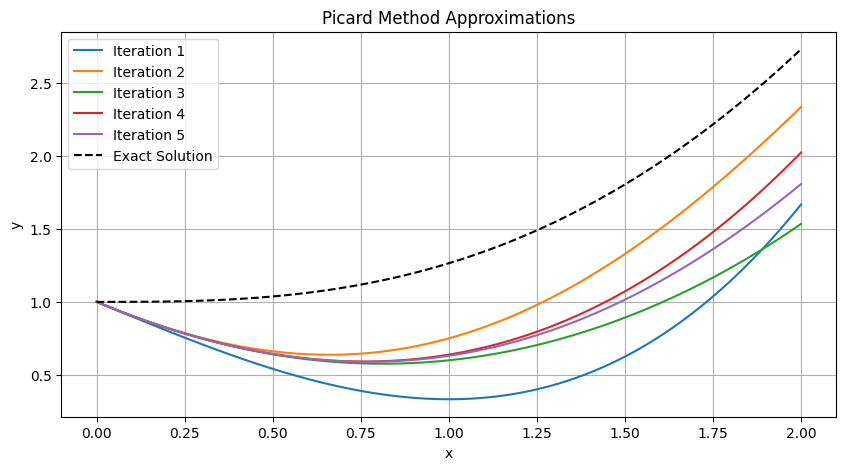

In [23]:
# Visualization
plt.figure(figsize=(10, 5))
for i, y_approx in enumerate(picard_results[1:], 1):
  plt.plot(x_vals, y_approx, label=f'Iteration {i}')
plt.plot(x_vals, exact_y, label='Exact Solution', linestyle='--', color='black')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Picard Method Approximations')
plt.legend()
plt.grid(True)
plt.show()

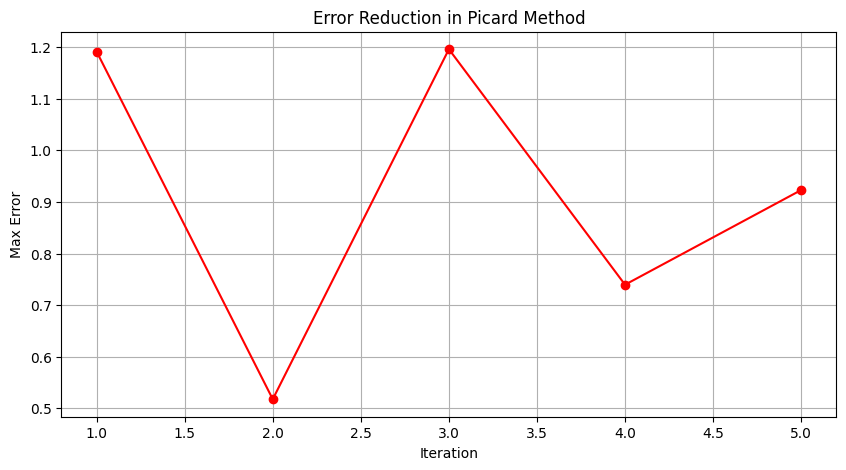

In [24]:
# Error Plot
plt.figure(figsize=(10, 5))
plt.plot(df['Iteration'], df['Max Error'], marker='o', color='red')
plt.xlabel('Iteration')
plt.ylabel('Max Error')
plt.title('Error Reduction in Picard Method')
plt.grid(True)
plt.show()